# 02 — Model 1: real-time route risk (regression)

* **Primary:** scikit-learn `RandomForestRegressor`
* **Benchmark:** `XGBRegressor` (second open-source framework, per the judging criteria)
* Metrics: MAE, RMSE, R², plus how well each model separates states above/below the 0.75 threshold,
  and single-row inference latency (the number that matters for "real-time" on LinuxONE).

In [1]:
from pathlib import Path

# Works both when Jupyter is started in the repo root and inside notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
ART = ROOT / "artifacts"
DATA.mkdir(exist_ok=True)
ART.mkdir(exist_ok=True)

import json
import platform
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

spec = json.loads((ART / "feature_spec.json").read_text())
FEATURES = spec["model1_features"]
THRESHOLD = spec["risk_threshold"]

df = pd.read_csv(DATA / "model1_training.csv")
X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df["risk_score"], test_size=0.2, random_state=spec["seed"])
len(X_train), len(X_test)

(16000, 4000)

In [2]:
models = {
    "baseline_mean": DummyRegressor(strategy="mean"),
    # Depth/leaf limits keep the saved model small (tens of MB unconstrained) and inference fast
    "random_forest": RandomForestRegressor(
        n_estimators=100, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=spec["seed"]),
    "xgboost": xgb.XGBRegressor(
        n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
        random_state=spec["seed"]),
}

rows = []
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    pred = np.clip(model.predict(X_test), 0, 1)
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
        "precision@thr": precision_score(y_test >= THRESHOLD, pred >= THRESHOLD, zero_division=0),
        "recall@thr": recall_score(y_test >= THRESHOLD, pred >= THRESHOLD, zero_division=0),
        "fit_seconds": fit_s,
    })
metrics = pd.DataFrame(rows).set_index("model").round(4)
metrics

,MAE,RMSE,R2,precision@thr,recall@thr,fit_seconds
model,,,,,,
baseline_mean,0.2711,0.3128,-0.0004,0.0000,0.000,0.0228
random_forest,0.0325,0.0442,0.9800,0.9191,0.891,1.1490
xgboost,0.0263,0.0334,0.9886,0.9502,0.912,0.5463


Recall above the threshold is the safety-relevant number: a missed high-risk state is worse than an unnecessary alert.

In [3]:
# Single-row latency, as seen by the live pipeline (one convoy update at a time)
rf, xgbm = models["random_forest"], models["xgboost"]
rf.set_params(n_jobs=1)   # thread start-up dominates for one row
one = X_test.iloc[[0]]

def latency_ms(model, reps=200):
    model.predict(one)
    t0 = time.perf_counter()
    for _ in range(reps):
        model.predict(one)
    return 1000 * (time.perf_counter() - t0) / reps

latency = {"random_forest": latency_ms(rf), "xgboost": latency_ms(xgbm)}
{k: f"{v:.2f} ms" for k, v in latency.items()}

{'random_forest': '6.26 ms', 'xgboost': '2.28 ms'}

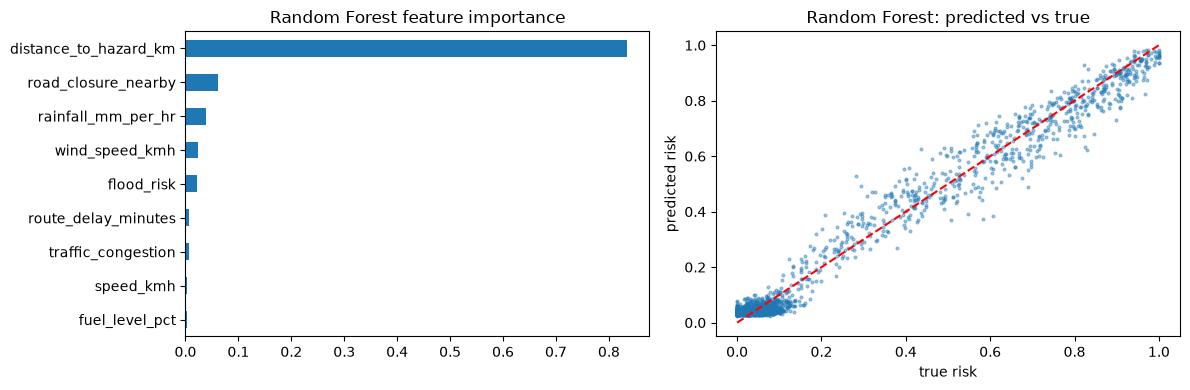

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(
    ax=axes[0], title="Random Forest feature importance")
sample = X_test.sample(2000, random_state=0)
axes[1].scatter(y_test.loc[sample.index], rf.predict(sample), s=4, alpha=0.4)
axes[1].plot([0, 1], [0, 1], "r--")
axes[1].set_xlabel("true risk")
axes[1].set_ylabel("predicted risk")
axes[1].set_title("Random Forest: predicted vs true")
plt.tight_layout()

## Save artifacts

* Random Forest → `joblib` (load it with the **same scikit-learn version** it was saved with).
* XGBoost → native JSON format, which is portable across architectures and byte orders.

The safest LinuxONE workflow is simply to re-run notebooks 01–03 there: everything is seeded and trains in seconds to minutes.

In [5]:
joblib.dump(rf, ART / "model1_rf.joblib", compress=3)
xgbm.save_model(ART / "model1_xgb.json")

report = {
    "metrics": metrics.reset_index().to_dict(orient="records"),
    "single_row_latency_ms": latency,
    "trained_on": {"machine": platform.machine(), "python": platform.python_version(),
                   "sklearn": sklearn.__version__, "xgboost": xgb.__version__},
}
(ART / "model1_report.json").write_text(json.dumps(report, indent=2))
print("Saved model1_rf.joblib, model1_xgb.json, model1_report.json")

Saved model1_rf.joblib, model1_xgb.json, model1_report.json
